<a href="https://colab.research.google.com/github/m1Febriansyah/244107020199-ML-12/blob/main/JS03_Praktikum01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
	import pandas as pd
	import numpy as np
	from sklearn.model_selection import train_test_split
	from sklearn.compose import ColumnTransformer
	from sklearn.preprocessing import OneHotEncoder, StandardScaler
	from sklearn.pipeline import Pipeline
	from sklearn.impute import SimpleImputer
	from sklearn.linear_model import LogisticRegression
	from sklearn.feature_selection import chi2, SelectKBest, RFE
	from sklearn.metrics import accuracy_score, classification_report

  	# Load Data
	df = pd.read_csv("Titanic-Dataset.csv")

	# Pisahkan Survived
	y = df["Survived"].astype(int)
	X = df.drop(columns=["Survived"])

	# Buat list variabel numerik dan kategorikal
	# Akan digunakan untuk proses seleksi fitur
	# Name tidak akan digunakan karena tidak relevan
	num_cols = ["Age", "SibSp", "Parch", "Fare"]
	cat_cols = ["Pclass", "Sex", "Embarked"]

In [ ]:
	# Ekstaksi Fitur dengan Pipeline

	# Data Numerik
	num_tf = Pipeline([
	    ("imputer", SimpleImputer(strategy="median")),
	    ("scaler", StandardScaler())
	])

	# Data Kategorikal
	cat_tf = Pipeline([
	    ("imputer", SimpleImputer(strategy="most_frequent")),
	    ("onehot", OneHotEncoder(handle_unknown="ignore"))
	])

In [ ]:
	# Buat Fitur FamilySize
	X["FamilySize"] = X["SibSp"].fillna(0) + X["Parch"].fillna(0) + 1

	# Tambahkan FamilySize pada kelompok numerikal
	preprocess = ColumnTransformer([
	    ("num", num_tf, num_cols + ["FamilySize"]),
	    ("cat", cat_tf, cat_cols),
	])

In [ ]:
	from sklearn.feature_selection import f_classif
	selector_filter = SelectKBest(score_func=f_classif, k=5)
 	# Seleksi fitur dengan SelectKBest
	# Fungsi tersebut akan menggunakan analisis variance
	# Baca: https://scikit-learn.org/stable/modules/feature_selection.html#univariate-feature-selection

	from sklearn.feature_selection import f_classif
	selector_filter = SelectKBest(score_func=f_classif, k=5)

	# Buat pipeline final (INGAT INI HANYA PIPELINE, BELUM MEMPROSES DATA)
	pipe_filter = Pipeline([
	    ("prep", preprocess), # menjalankan pipeline preprocessing
	    ("sel", selector_filter), # menjalankan pipeline seleksi fitur
	    ("clf", LogisticRegression(max_iter=1000)) # uji dengan model sederhana -> Logistic Regression
	])

In [ ]:
	# Lakukan pelatihan dan uji model
	X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y, test_size=0.2, random_state=42)

	pipe_filter.fit(X_train, y_train)
	pred = pipe_filter.predict(X_test)
	print("=== Filter (ANOVA) + LR ===")
	print("Accuracy:", accuracy_score(y_test, pred))
	print(classification_report(y_test, pred))

=== Filter (ANOVA) + LR ===
Accuracy: 0.776536312849162
              precision    recall  f1-score   support

           0       0.80      0.85      0.82       110
           1       0.73      0.67      0.70        69

    accuracy                           0.78       179
   macro avg       0.77      0.76      0.76       179
weighted avg       0.77      0.78      0.77       179



In [ ]:
	# 1) Nama fitur setelah preprocess
	feat_names = pipe_filter.named_steps["prep"].get_feature_names_out()
	print("Nama fitur:", feat_names)
	print("\n")

	# 2) Mask & skor fitur terpilih (SelectKBest)
	sel = pipe_filter.named_steps["sel"]
	mask = sel.get_support()
	selected_names = feat_names[mask]
	selected_scores = sel.scores_[mask]
	top = sorted(zip(selected_names, selected_scores), key=lambda t: t[1], reverse=True)[:10]
	print("Top fitur:", top)

Nama fitur: ['num__Age' 'num__SibSp' 'num__Parch' 'num__Fare' 'num__FamilySize'
 'cat__Pclass_1' 'cat__Pclass_2' 'cat__Pclass_3' 'cat__Sex_female'
 'cat__Sex_male' 'cat__Embarked_C' 'cat__Embarked_Q' 'cat__Embarked_S']


Top fitur: [('cat__Sex_female', np.float64(306.5932488951883)), ('cat__Sex_male', np.float64(306.59324889518797)), ('cat__Pclass_3', np.float64(80.33862734392042)), ('cat__Pclass_1', np.float64(73.99727564291717)), ('num__Fare', np.float64(58.31490728198491))]


In [11]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

df = pd.read_csv('properti_multi_kota.csv')
df.head()

,sumber,lokasi,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,harga
0,uas-properti/Jabodetabek,Tangerang,30.0,NaN,3.0,3.0,33.0,2.037543e+08
1,uas-properti/Jabodetabek,Bekasi,122.0,NaN,5.0,4.0,19.0,1.058032e+09
2,uas-properti/Jabodetabek,Bekasi,142.8,NaN,1.0,1.0,9.0,1.335793e+09
3,uas-properti/Jabodetabek,Bekasi,152.6,NaN,4.0,3.0,6.0,1.613771e+09
4,uas-properti/Jabodetabek,Depok,61.2,NaN,1.0,1.0,9.0,5.221562e+08


In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64650 entries, 0 to 64649
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   sumber              64650 non-null  object 
 1   lokasi              64650 non-null  object 
 2   luas_m2             64650 non-null  float64
 3   luas_bangunan       63046 non-null  float64
 4   jumlah_kamar        64254 non-null  float64
 5   jumlah_kamar_mandi  64242 non-null  float64
 6   usia_bangunan       4789 non-null   float64
 7   harga               64650 non-null  float64
dtypes: float64(6), object(2)
memory usage: 3.9+ MB


In [12]:
df.isnull().sum()

,0
sumber,0
lokasi,0
luas_m2,0
luas_bangunan,1604
jumlah_kamar,396
jumlah_kamar_mandi,408
usia_bangunan,59861
harga,0


In [ ]:
# Menggunakan median agar tidak terpengaruh outlier ekstrem pada dataset properti
df['luas_bangunan'] = df['luas_bangunan'].fillna(df['luas_bangunan'].median())
df['jumlah_kamar'] = df['jumlah_kamar'].fillna(df['jumlah_kamar'].median())
df['jumlah_kamar_mandi'] = df['jumlah_kamar_mandi'].fillna(df['jumlah_kamar_mandi'].median())
df['usia_bangunan'] = df['usia_bangunan'].fillna(df['usia_bangunan'].median())

In [14]:
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64650 entries, 0 to 64649
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   sumber              64650 non-null  object 
 1   lokasi              64650 non-null  object 
 2   luas_m2             64650 non-null  float64
 3   luas_bangunan       63046 non-null  float64
 4   jumlah_kamar        64254 non-null  float64
 5   jumlah_kamar_mandi  64242 non-null  float64
 6   usia_bangunan       4789 non-null   float64
 7   harga               64650 non-null  float64
dtypes: float64(6), object(2)
memory usage: 3.9+ MB


,0
sumber,0
lokasi,0
luas_m2,0
luas_bangunan,1604
jumlah_kamar,396
jumlah_kamar_mandi,408
usia_bangunan,59861
harga,0


In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

In [15]:
# === EKSTRAKSI FITUR ===

# 1. TotalRuangan: gabungan jumlah kamar tidur dan kamar mandi
df["TotalRuangan"] = df["jumlah_kamar"] + df["jumlah_kamar_mandi"]

# 2. SumberKategori: mengambil prefix/kategori utama dari kolom sumber (sebelum tanda '/')
df["SumberKategori"] = df["sumber"].astype(str).str.split('/').str[0]

# 3. KategoriLuas: mengelompokkan luas tanah (luas_m2) menjadi kategori ukuran properti
df["KategoriLuas"] = pd.cut(
    df["luas_m2"],
    bins=[0, 60, 120, 250, 1000, float('inf')],
    labels=["Kecil", "Sedang", "Besar", "SangatBesar", "Komersial/Lahan"]
)

# 4. RasioBangunan: rasio luas bangunan terhadap luas tanah
df["RasioBangunan"] = df["luas_bangunan"] / df["luas_m2"].replace(0, np.nan)

# 5. HargaPerM2: harga properti dibagi luas tanah (m2)
df["HargaPerM2"] = df["harga"] / df["luas_m2"].replace(0, np.nan)

print("Hasil Ekstraksi Fitur")
df[["lokasi", "SumberKategori", "luas_m2", "KategoriLuas", "TotalRuangan", "RasioBangunan", "HargaPerM2"]].head()

Hasil Ekstraksi Fitur


,lokasi,SumberKategori,luas_m2,KategoriLuas,TotalRuangan,RasioBangunan,HargaPerM2
0,Tangerang,uas-properti,30.0,Kecil,6.0,NaN,6.791809e+06
1,Bekasi,uas-properti,122.0,Besar,9.0,NaN,8.672391e+06
2,Bekasi,uas-properti,142.8,Besar,2.0,NaN,9.354291e+06
3,Bekasi,uas-properti,152.6,Besar,7.0,NaN,1.057517e+07
4,Depok,uas-properti,61.2,Sedang,2.0,NaN,8.531964e+06


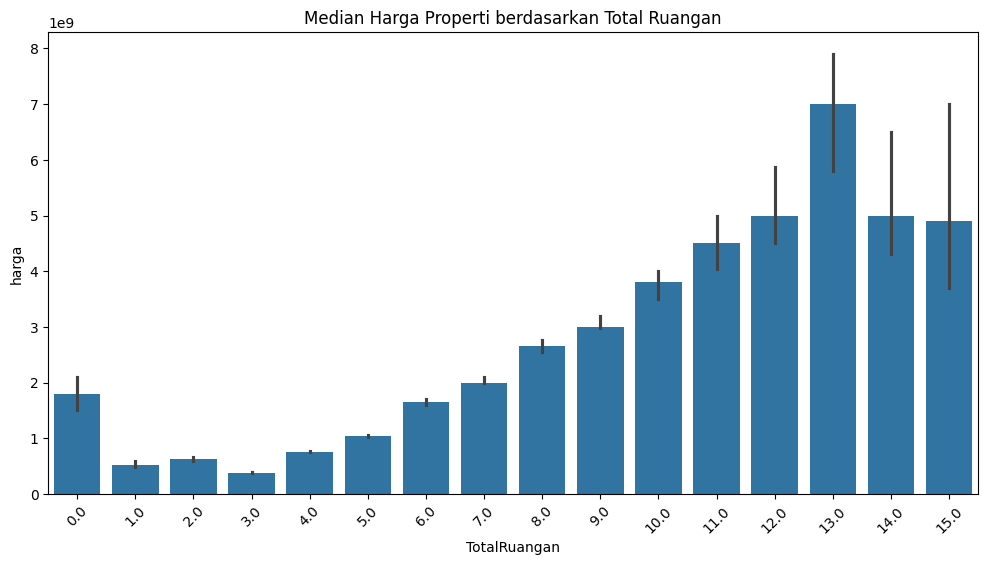

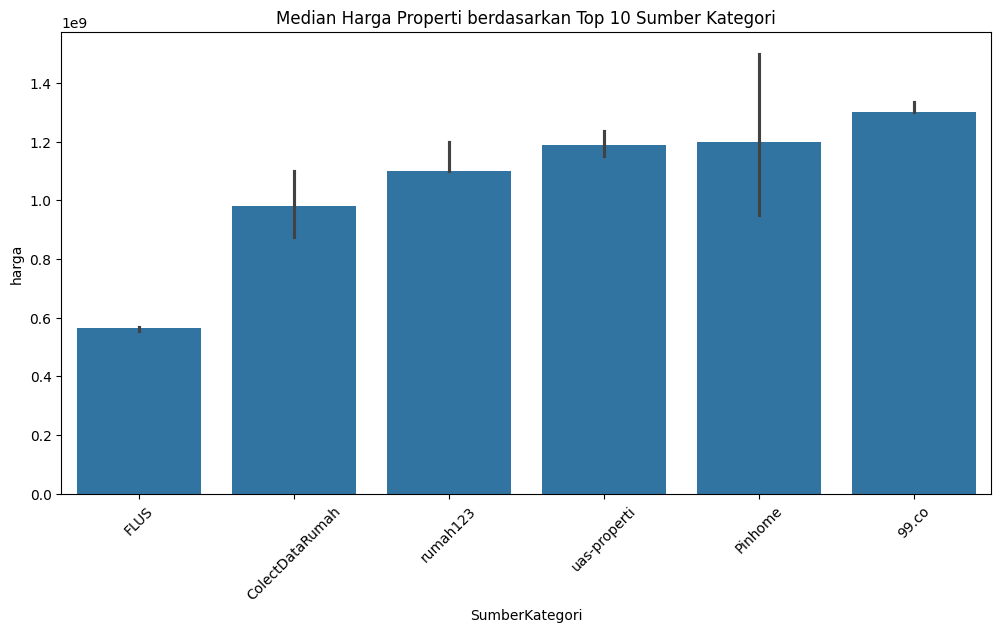

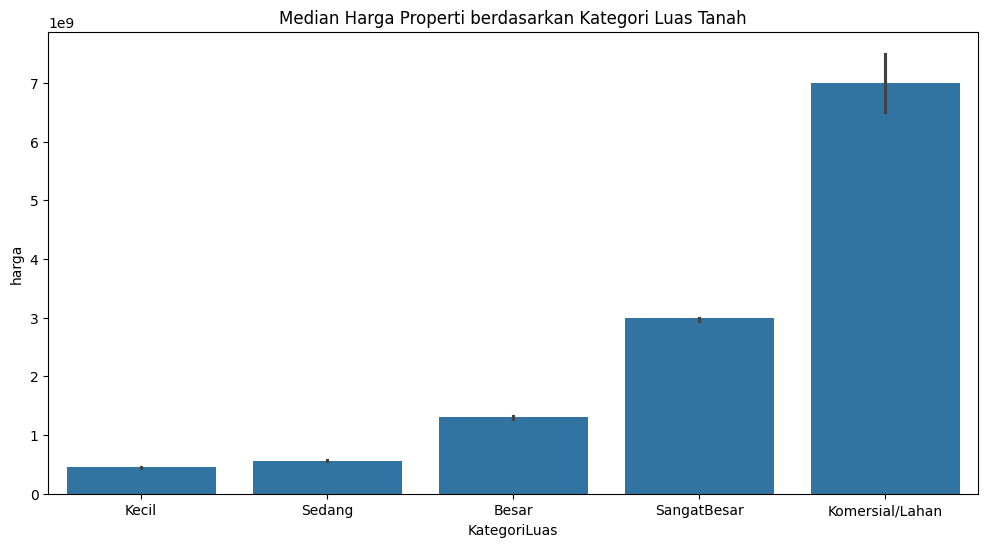

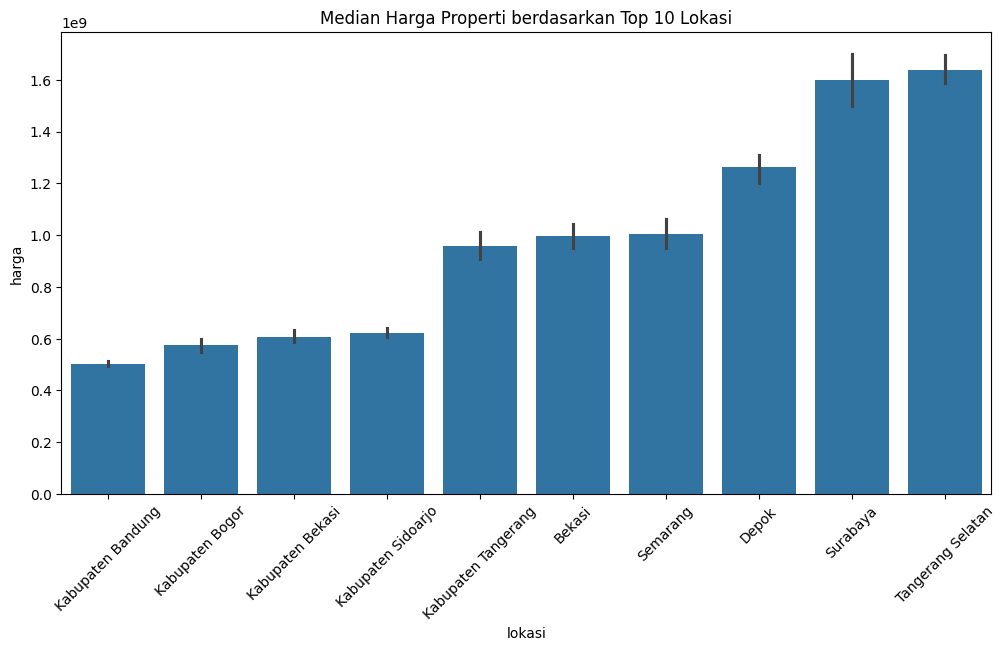

In [18]:
# === VISUALISASI FITUR HASIL EKSTRAKSI ===

# 1. Median Harga berdasarkan Total Ruangan (dibatasi <= 15 ruangan agar grafik terbaca jelas)
plt.figure(figsize=(12, 6))
sns.barplot(x="TotalRuangan", y="harga", data=df[df["TotalRuangan"] <= 15], estimator="median")
plt.title("Median Harga Properti berdasarkan Total Ruangan")
plt.xticks(rotation=45)
plt.show()

# 2. Median Harga berdasarkan 10 Sumber Kategori Teratas
top_sumber = df["SumberKategori"].value_counts().nlargest(10).index
plt.figure(figsize=(12, 6))
sns.barplot(
    x="SumberKategori", y="harga",
    data=df[df["SumberKategori"].isin(top_sumber)],
    estimator="median",
    order=df[df["SumberKategori"].isin(top_sumber)].groupby("SumberKategori")["harga"].median().sort_values().index
)
plt.title("Median Harga Properti berdasarkan Top 10 Sumber Kategori")
plt.xticks(rotation=45)
plt.show()

# 3. Median Harga berdasarkan Kategori Luas Tanah
plt.figure(figsize=(12, 6))
sns.barplot(
    x="KategoriLuas", y="harga", data=df,
    estimator="median",
    order=["Kecil", "Sedang", "Besar", "SangatBesar", "Komersial/Lahan"]
)
plt.title("Median Harga Properti berdasarkan Kategori Luas Tanah")
plt.show()

# 4. Median Harga berdasarkan 10 Lokasi Teratas
top_lokasi = df["lokasi"].value_counts().nlargest(10).index
plt.figure(figsize=(12, 6))
sns.barplot(
    x="lokasi", y="harga",
    data=df[df["lokasi"].isin(top_lokasi)],
    estimator="median",
    order=df[df["lokasi"].isin(top_lokasi)].groupby("lokasi")["harga"].median().sort_values().index
)
plt.title("Median Harga Properti berdasarkan Top 10 Lokasi")
plt.xticks(rotation=45)
plt.show()